In [4]:
import numpy as np
from sklearn.covariance import GraphicalLasso, GraphicalLassoCV
from sklearn.preprocessing import StandardScaler
import mlflow
import pandas as pd
import torch
from tqdm import tqdm
from inverse_covariance import QuicGraphLassoCV, QuicGraphicalLassoCV, QuicGraphicalLasso

from simulation_studies.generate_synthetic_vine_data import generate_synthetic_vine_data
from dev_indep_vines_helpers import *

## Functions to run and analyze GGM:

In [5]:
def p_to_corr(matrix):

            diag_sqrt = np.diag(matrix).reshape(matrix.shape[0],1) ** 0.5
            matrix_std_multiplied = diag_sqrt @ diag_sqrt.T
            
            return -1 * matrix / matrix_std_multiplied

def run_graph_lasso(seed_value=1,
                    seed_value_copula=1,
        dimensionality=10,
        Independence_tree=3,
        vine_type="R-Vine",
        N_train=100,
        N_validate=25,
        N_test=10000,
        tau_mean=0.3,
        tau_range=0.2,
        negative_tau=True):

    synthetic_data_dict = generate_synthetic_vine_data(
        seed_value=seed_value,
        seed_value_copula=seed_value_copula,
        dimensionality=dimensionality,
        Independence_tree=Independence_tree,
        vine_type=vine_type,
        N_train=N_train,
        N_validate=N_validate,
        N_test=N_test,
        tau_mean=tau_mean, 
        tau_range=tau_range, 
        negative_tau=negative_tau
    )
    
    y_train = synthetic_data_dict["train_data"]
    y_validate = synthetic_data_dict["validate_data"]
    
    
    y_all = torch.vstack([y_train, y_validate])
        
    Y_all = y_all.numpy()
    Y_train = y_train.numpy()
    # Normalize the data
    scaler = StandardScaler()
    Y_all_norm = scaler.fit_transform(Y_all)
    Y_train_norm = scaler.transform(Y_train)
    
    cv_model = QuicGraphicalLassoCV().fit(Y_all_norm)
    cov = QuicGraphicalLasso(lam=cv_model.lam_).fit(Y_train_norm)
        #lam=int or np.ndarray,  # (optional) Initial penalty (scalar or matrix) 
        #lams=int or list,       # If int, determines the number of grid points 
                                # per refinement
        #n_refinements=int,      # Number of times the grid is refined
        #cv=int,                 # Number of folds or sklearn CV object
        #score_metric=str,       # One of 'log_likelihood' (default), 'frobenius', 
                                #        'kl', or 'quadratic'
        #init_method=str,        # Initial covariance estimate: 'corrcoef' or 'cov'
        # # X is data matrix (n_samples, n_features) 
        
    p_matrix = cov.precision_ #emp_cov
    
    p_matrix = np.around(p_matrix, decimals=3) #get_precision(), decimals=3)
    
    # Get the lower triangular indices, including the diagonal
    lower_triangular_indices = np.tril_indices_from(p_matrix, k=-1)
    
    # results in the precision matrix elements being the conditional correlations
    p_matrix = p_matrix
    c_matrix = p_to_corr(p_matrix)

    # Extract the corresponding entries from the precision matrix
    entries_abs = np.abs(p_matrix[lower_triangular_indices])
    entries_abs_c = np.abs(c_matrix[lower_triangular_indices])

    # Create a list of tuples (row_number, col_number, precision_matrix_entry)
    data = list(zip(lower_triangular_indices[0], lower_triangular_indices[1], entries_abs, entries_abs_c))

    # Convert the list of tuples into a Pandas DataFrame
    df = pd.DataFrame(data, columns=['var_row', 'var_col', 'ggm_p_matrix_abs', 'ggm_c_matrix_abs'])
    
    true_ci_graph = synthetic_data_dict["df_true_structure"]
    df = pd.merge(df, true_ci_graph, on=['var_row', 'var_col'])
    
    return df

In [30]:
######################################################################################################################################################
################  Version with gaussian model to compare to gauss graphical model  ################
######################################################################################################################################################
def run_graph_lasso(seed_value=1,
                    seed_value_copula=1,
        dimensionality=10,
        Independence_tree=3,
        vine_type="R-Vine",
        N_train=100,
        N_validate=25,
        N_test=10000,
        tau_mean=0.3,
        tau_range=0.2,
        negative_tau=True):

    synthetic_data_dict = generate_synthetic_vine_data(
        seed_value=seed_value,
        seed_value_copula=seed_value_copula,
        dimensionality=dimensionality,
        Independence_tree=Independence_tree,
        vine_type=vine_type,
        N_train=N_train,
        N_validate=N_validate,
        N_test=N_test,
        tau_mean=tau_mean, 
        tau_range=tau_range, 
        negative_tau=negative_tau
    )
    y_train = synthetic_data_dict["train_data"]
    y_validate = synthetic_data_dict["validate_data"]

    y_all = torch.vstack([y_train, y_validate])
    Y_all = y_all.numpy()

    # Normalize the data
    scaler = StandardScaler()
    Y_all_norm = scaler.fit_transform(Y_all)
    

    # 1. Graphical Lasso
    cv_model = QuicGraphicalLassoCV().fit(Y_all_norm)
    cov = QuicGraphicalLasso(lam=cv_model.lam_).fit(Y_all_norm)
    p_matrix = cov.precision_
    p_matrix = np.around(p_matrix, decimals=3)
    
    # 2. Vanilla Gaussian model (no penalty)
    emp_cov = np.cov(Y_all_norm, rowvar=False)
    gm_precision = np.linalg.inv(emp_cov)
    gm_precision = np.around(gm_precision, decimals=3)

    def p_to_corr(matrix):
        diag_sqrt = np.diag(matrix).reshape(matrix.shape[0],1) ** 0.5
        matrix_std_multiplied = diag_sqrt @ diag_sqrt.T
        return -1 * matrix / matrix_std_multiplied

    c_matrix = p_to_corr(p_matrix)
    gm_c_matrix = p_to_corr(gm_precision)
    
    # Lower-triangular indices, excluding diagonal (for both precision matrices)
    lower_triangular_indices = np.tril_indices_from(p_matrix, k=-1)
    
    # GGM (Graphical Lasso) values
    entries_abs = np.abs(p_matrix[lower_triangular_indices])
    entries_abs_c = np.abs(c_matrix[lower_triangular_indices])

    # Gaussian vanilla (no penalty) values
    gm_entries_abs = np.abs(gm_precision[lower_triangular_indices])
    gm_entries_abs_c = np.abs(gm_c_matrix[lower_triangular_indices])

    data = list(zip(
        lower_triangular_indices[0], lower_triangular_indices[1], 
        entries_abs, entries_abs_c, 
        gm_entries_abs, gm_entries_abs_c
    ))

    df = pd.DataFrame(data, columns=[
        'var_row', 'var_col', 
        'ggm_p_matrix_abs', 'ggm_c_matrix_abs', 
        'gm_p_matrix_abs', 'gm_c_matrix_abs'
    ])
    
    true_ci_graph = synthetic_data_dict["df_true_structure"]
    df = pd.merge(df, true_ci_graph, on=['var_row', 'var_col'])
    
    return df

In [31]:
def eval_ggm(N_train=100,
             N_validate=25,
             N_test=10000,
             dimensionality = 10,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100),
             tau_mean=0.3,
             tau_range=0.2,
             negative_tau=True):

    list_df = []
    for seed in tqdm(seed_range):
        if seed_value_copula_fixed == False:
            seed_copula = seed
        else:            
            seed_copula = seed_value_copula_fixed

        df = run_graph_lasso(seed_value=seed,
                            seed_value_copula=seed_copula,
                            dimensionality=dimensionality,
                            Independence_tree=Independence_tree,
                            vine_type=vine_type,
                            N_train=N_train,
                            N_validate=N_validate,
                            N_test=N_test,
                            tau_mean=tau_mean,
                            tau_range=tau_range,
                            negative_tau=negative_tau)

        list_df.append(df)



    list_num = 0
    list_auc = []
    for i in range(len(list_df)):
        auc = plot_roc_curve(list_df[i]["dependence"], 
                    list_df[i]["ggm_p_matrix_abs"],
                    color="tab:blue" 
                    #label="seed_{}".format(i+1)
                    )
        list_auc.append(auc)
    plot_roc_curve(list_df[i]["dependence"], 
                    np.repeat(1, len(list_df[i]["ggm_p_matrix_abs"])),
                    color="dimgray" 
                    #label="random".format(i+1)
                    )
    #plt.legend()
    aucs = np.array(list_auc)
    
    return aucs

In [32]:
######################################################################################################################################################
################  Version with gaussian model to compare to gauss graphical model  ################
######################################################################################################################################################
from sklearn.metrics import roc_auc_score
def plot_roc_curve(y_true, y_score, plot=True, color=None):
    if plot:
        # plotting code here
        pass
    return roc_auc_score(y_true, y_score)

def eval_ggm(N_train=100,
             N_validate=25,
             N_test=10000,
             dimensionality=10,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0, 100),
             tau_mean=0.3,
             tau_range=0.2,
             negative_tau=True):
    from tqdm import tqdm
    import numpy as np

    metrics = [
        "ggm_p_matrix_abs",
        "ggm_c_matrix_abs",
        "gm_p_matrix_abs",
        "gm_c_matrix_abs",
    ]
    auc_dict = {m: [] for m in metrics}

    for seed in tqdm(seed_range):
        if seed_value_copula_fixed is False:
            seed_copula = seed
        else:
            seed_copula = seed_value_copula_fixed

        df = run_graph_lasso(
            seed_value=seed,
            seed_value_copula=seed_copula,
            dimensionality=dimensionality,
            Independence_tree=Independence_tree,
            vine_type=vine_type,
            N_train=N_train,
            N_validate=N_validate,
            N_test=N_test,
            tau_mean=tau_mean,
            tau_range=tau_range,
            negative_tau=negative_tau,
        )

        # Evaluate each metric
        labels = df["dependence"]
        for m in metrics:
            scores = df[m]
            auc = plot_roc_curve(labels, scores, plot=False)  # plot=False: just get auc
            auc_dict[m].append(auc)

    # Convert to numpy arrays (optional)
    for m in auc_dict:
        auc_dict[m] = np.array(auc_dict[m])

    return auc_dict

## Compare GGM to GM

In [14]:
aucs = eval_ggm(N_train=100,
             N_validate=25,
             N_test=10000,
             dimensionality=10,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0, 100),
             tau_mean=0.3,
             tau_range=0.2,
             negative_tau=True)

100%|██████████| 100/100 [03:53<00:00,  2.33s/it]


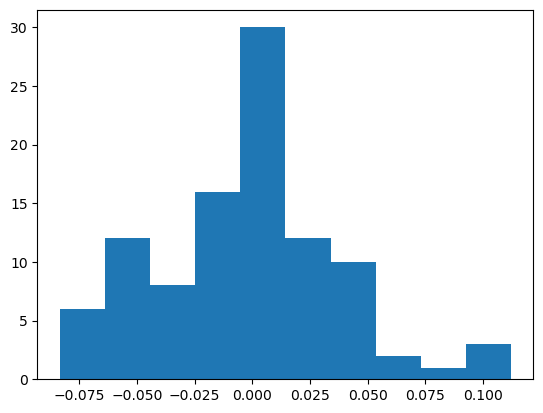

In [18]:
plt.hist(aucs["ggm_c_matrix_abs"] - aucs["gm_c_matrix_abs"])
plt.show()

In [16]:
print(np.mean(aucs["ggm_c_matrix_abs"]) )
print(np.mean(aucs["gm_c_matrix_abs"])  )

0.8518849206349206
0.8545039682539681


In [33]:
aucs_20 = eval_ggm(N_train=100,
             N_validate=25,
             N_test=10000,
             dimensionality=20,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0, 10),
             tau_mean=0.3,
             tau_range=0.2,
             negative_tau=True)

100%|██████████| 10/10 [00:40<00:00,  4.09s/it]


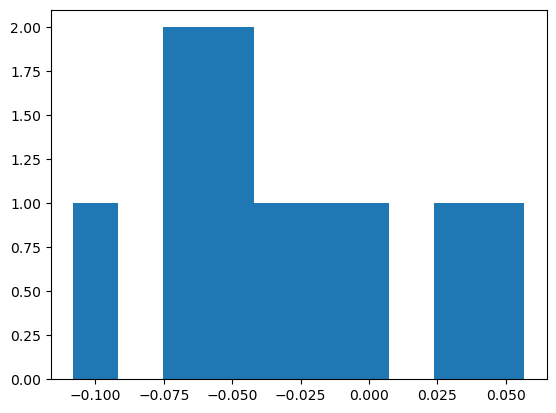

In [34]:
plt.hist(aucs_20["ggm_c_matrix_abs"] - aucs_20["gm_c_matrix_abs"])
plt.show()

In [20]:
D=20
D*(D-1)/2

190.0

In [25]:
aucs_50 = eval_ggm(N_train=100,
             N_validate=25,
             N_test=10000,
             dimensionality=50,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0, 10),
             tau_mean=0.3,
             tau_range=0.2,
             negative_tau=True)

100%|██████████| 10/10 [06:41<00:00, 40.16s/it]


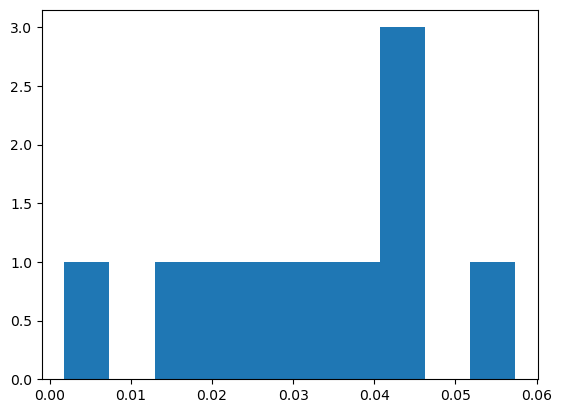

In [26]:
plt.hist(aucs_50["ggm_c_matrix_abs"] - aucs_50["gm_c_matrix_abs"])
plt.show()

In [29]:
aucs_50["ggm_c_matrix_abs"]

array([0.65785924, 0.69229237, 0.68267551, 0.67280489, 0.65245015,
       0.6792065 , 0.69192941, 0.70219511, 0.6784356 , 0.65784639])

## Baseline: Run GGM and Store:

### R-Vine

In [32]:
m = np.ones((10,10))
diag = np.diag(m).reshape(10,1)
diag @ diag.T

array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [33]:
m.shape[0]

10

In [36]:
p_to_corr(m)

array([[-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
       [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.]])

In [12]:
N_train = 100
N_validate = 25

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,10))


 20%|██        | 2/10 [00:06<00:24,  3.00s/it]


KeyboardInterrupt: 

100%|██████████| 100/100 [04:07<00:00,  2.47s/it]


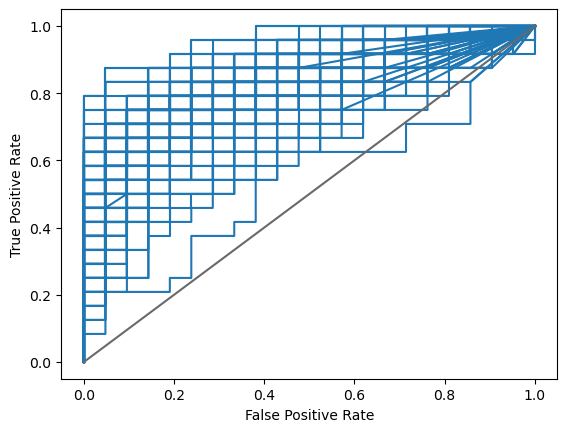

In [4]:
N_train = 100
N_validate = 25

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [03:52<00:24,  2.67s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [04:20<00:00,  2.60s/it]


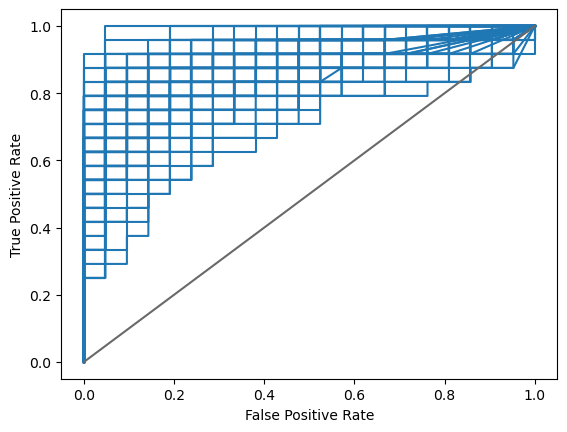

In [5]:
N_train = 400
N_validate = 100

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [04:51<00:31,  3.47s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [05:21<00:00,  3.22s/it]


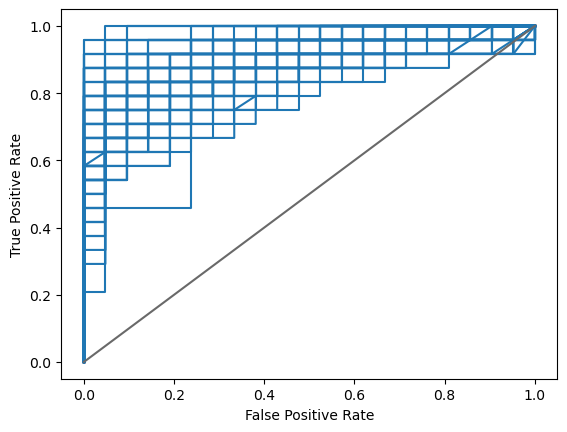

In [6]:
N_train = 1600
N_validate = 400

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [06:46<00:41,  4.64s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [07:25<00:00,  4.45s/it]


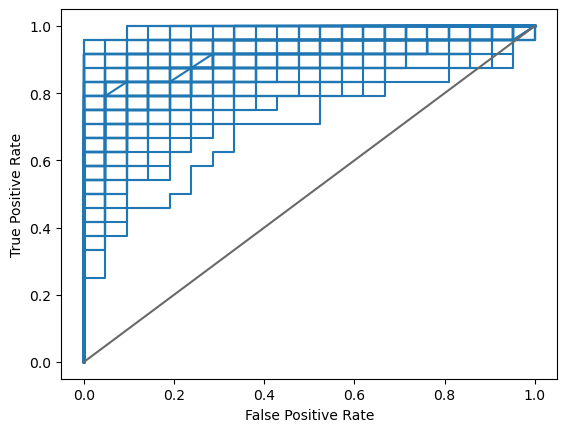

In [9]:
N_train = 8000
N_validate = 2000

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 25%|██▌       | 25/100 [09:48<37:59, 30.39s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [37:16<00:00, 22.37s/it]


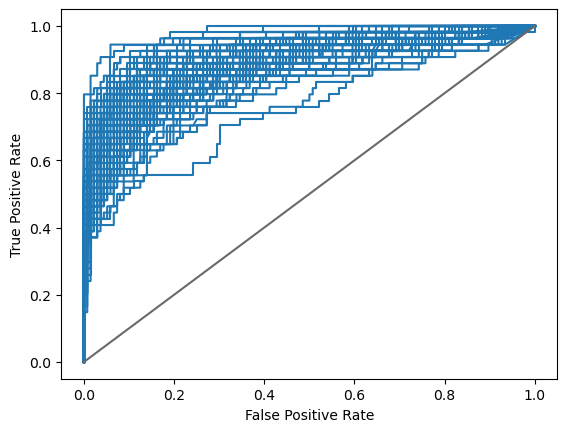

In [4]:
N_train = 1600
N_validate = 400

dimensionality = 20

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="R-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

### C-Vine

100%|██████████| 100/100 [04:03<00:00,  2.44s/it]


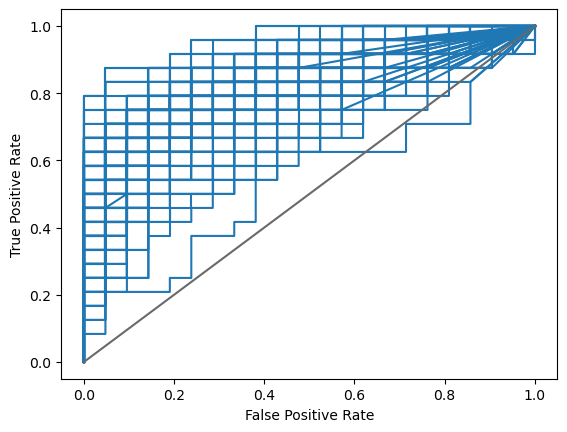

In [10]:
N_train = 100
N_validate = 25

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="cvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [03:48<00:23,  2.62s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [04:15<00:00,  2.55s/it]


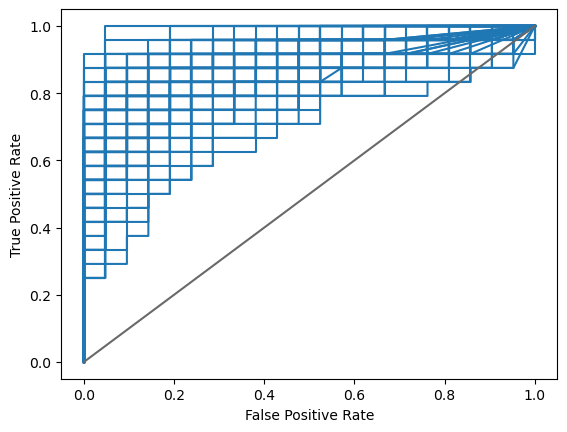

In [11]:
N_train = 400
N_validate = 100

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="cvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [04:50<00:31,  3.45s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [05:20<00:00,  3.20s/it]


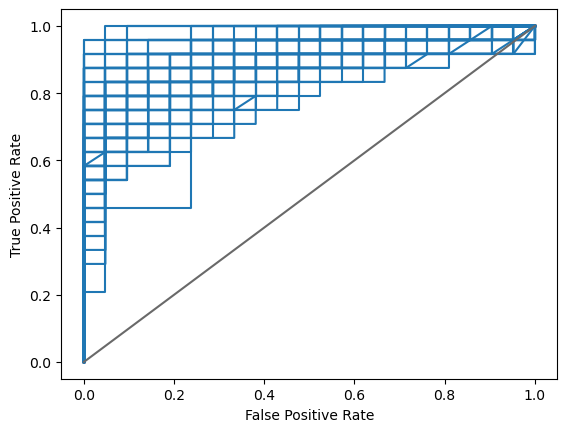

In [12]:
N_train = 1600
N_validate = 400

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="cvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [06:46<00:41,  4.61s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [07:24<00:00,  4.45s/it]


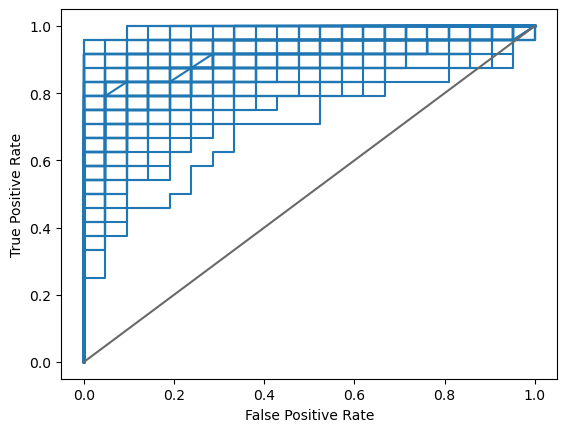

In [13]:
N_train = 8000
N_validate = 2000

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="cvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

100%|██████████| 20/20 [07:21<00:00, 22.09s/it]


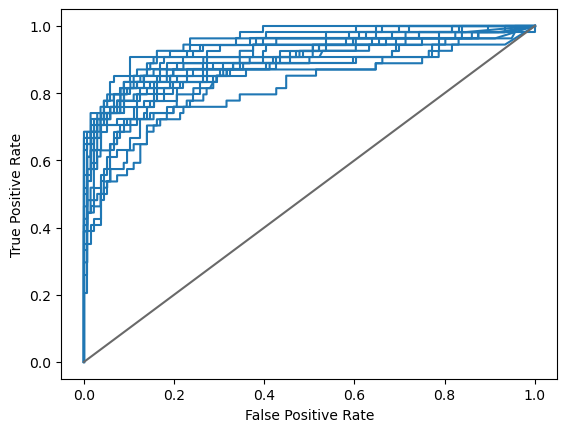

In [6]:
N_train = 1600
N_validate = 400

dimensionality = 20

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,20))

experiment_name="cvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

### D-Vine

100%|██████████| 100/100 [04:06<00:00,  2.47s/it]


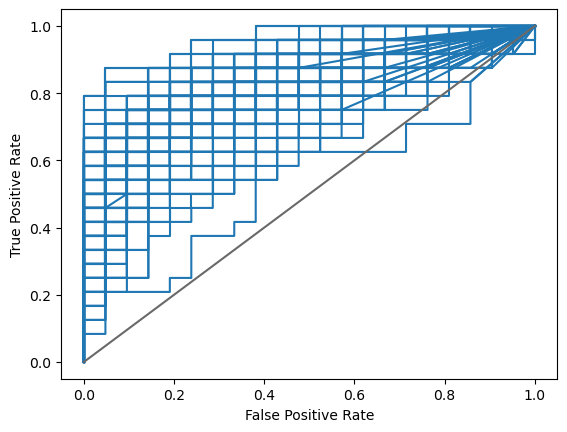

In [14]:
N_train = 100
N_validate = 25

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="D-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="dvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [03:49<00:23,  2.61s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [04:16<00:00,  2.57s/it]


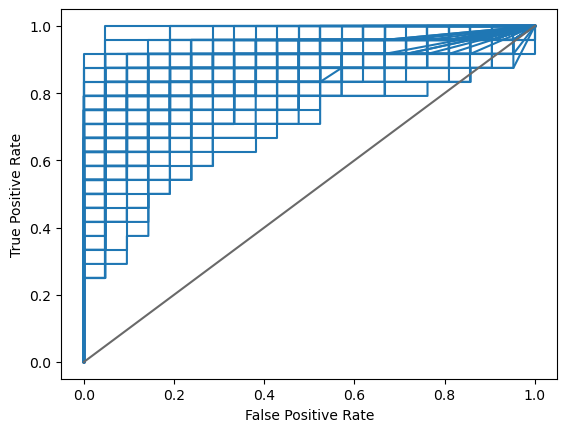

In [15]:
N_train = 400
N_validate = 100

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="D-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="dvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

100%|██████████| 100/100 [1:44:34<00:00, 62.74s/it]  


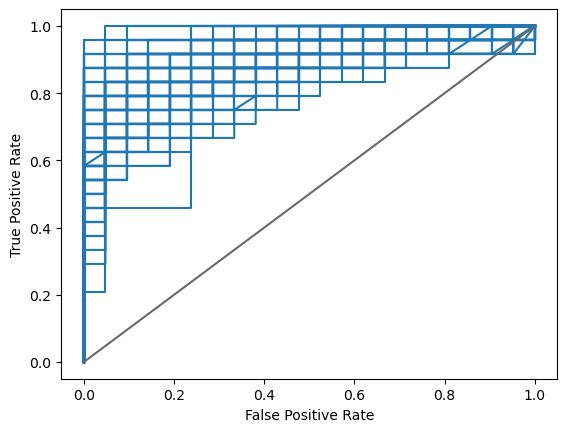

In [16]:
N_train = 1600
N_validate = 400

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="D-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="dvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

 91%|█████████ | 91/100 [2:20:33<03:40, 24.53s/it]   /Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
100%|██████████| 100/100 [3:08:57<00:00, 113.37s/it]


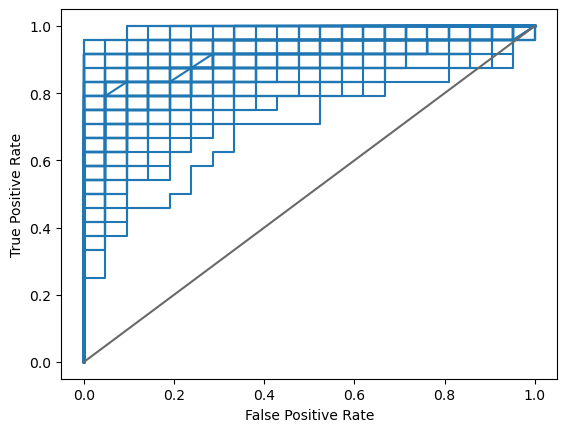

In [17]:
N_train = 8000
N_validate = 2000

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="D-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100))

experiment_name="dvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

auc_array = np.array(aucs)
np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

## Stronger Dependence: Run GGM and Store:

  0%|          | 0/100 [00:00<?, ?it/s]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/inverse_covariance/metrics.py:25: RuntimeWarning: invalid value encountered in multiply
  -np.sum(covariance * precision)
/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  1%|          | 1/100 [00:07<12:52,  7.80s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  2%|▏         | 2/100 [00:14<11:55,  7.31s/it]

array([0.92261905, 0.7609127 , 0.84821429, 0.81448413, 0.64484127,
       0.69642857, 0.80753968, 0.72222222, 0.72420635, 0.80357143,
       0.67261905, 0.73611111, 0.72519841, 0.65277778, 0.7718254 ,
       0.74801587, 0.75      , 0.74603175, 0.69642857, 0.57539683,
       0.74900794, 0.74007937, 0.79365079, 0.82539683, 0.75099206,
       0.63789683, 0.69444444, 0.59623016, 0.78075397, 0.48611111,
       0.9265873 , 0.72718254, 0.53670635, 0.56150794, 0.68452381,
       0.70238095, 0.83134921, 0.69444444, 0.83928571, 0.75198413,
       0.67261905, 0.78075397, 0.83134921, 0.81051587, 0.74206349,
       0.76984127, 0.75396825, 0.78373016, 0.67956349, 0.68849206,
       0.69246032, 0.76388889, 0.71031746, 0.77380952, 0.69642857,
       0.73214286, 0.80952381, 0.74007937, 0.64484127, 0.61111111,
       0.74404762, 0.88095238, 0.73809524, 0.66666667, 0.76587302,
       0.85912698, 0.79761905, 0.67460317, 0.91468254, 0.62599206,
       0.75297619, 0.88690476, 0.52579365, 0.73412698, 0.64682

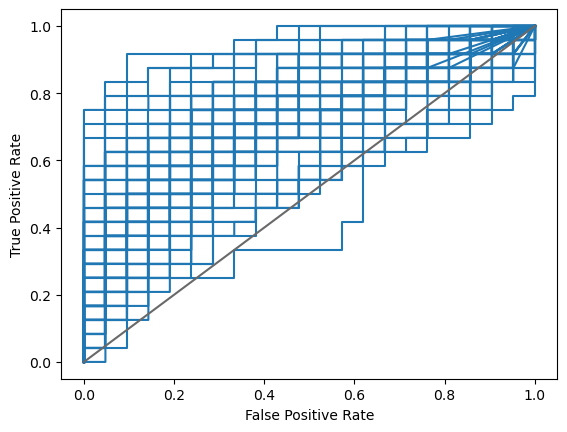

In [13]:
N_train = 1000
N_validate = 1000

dimensionality = 10

aucs = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100
                              ),
             tau_mean=0.5,
             tau_range=0.2,
             negative_tau=True)

aucs

#experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

#auc_array = np.array(aucs)
#np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

In [15]:
np.quantile(aucs, q=0.8)

0.796031746031746

In [16]:
np.quantile(aucs, q=0.2)

0.6664682539682539

(array([ 4.,  2.,  5.,  8., 19., 25., 16., 10.,  7.,  4.]),
 array([0.48611111, 0.53015873, 0.57420635, 0.61825397, 0.66230159,
        0.70634921, 0.75039683, 0.79444444, 0.83849206, 0.88253968,
        0.9265873 ]),
 <BarContainer object of 10 artists>)

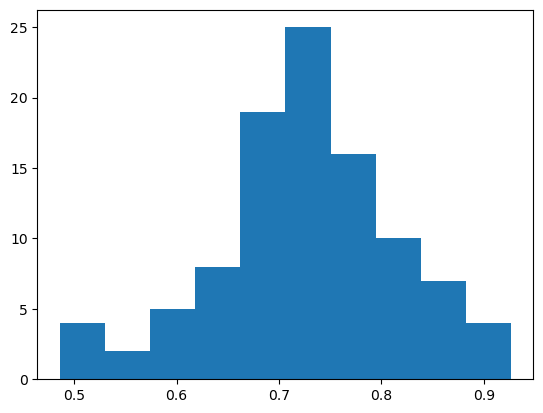

In [14]:
plt.hist(aucs)

  1%|          | 1/100 [00:07<11:41,  7.09s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  5%|▌         | 5/100 [00:35<11:14,  7.10s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  7%|▋         | 7/100 [00:49<11:01,  7.12s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  9%|▉         | 9/100 [01:04<10:58,  7.24s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encoun

array([0.84126984, 0.73611111, 0.8640873 , 0.80357143, 0.625     ,
       0.64087302, 0.8015873 , 0.73611111, 0.76289683, 0.83333333,
       0.68055556, 0.73015873, 0.75396825, 0.6984127 , 0.83531746,
       0.72916667, 0.71329365, 0.73015873, 0.59722222, 0.60416667,
       0.74503968, 0.75793651, 0.75992063, 0.82738095, 0.74404762,
       0.6031746 , 0.70634921, 0.63392857, 0.80456349, 0.56547619,
       0.86706349, 0.74007937, 0.50198413, 0.65277778, 0.64484127,
       0.7797619 , 0.88888889, 0.68055556, 0.8125    , 0.79166667,
       0.64484127, 0.74305556, 0.8234127 , 0.84325397, 0.73511905,
       0.77777778, 0.82142857, 0.72420635, 0.67063492, 0.70436508,
       0.74007937, 0.77083333, 0.69047619, 0.76388889, 0.7093254 ,
       0.70238095, 0.79265873, 0.8015873 , 0.61309524, 0.7202381 ,
       0.73015873, 0.85714286, 0.75      , 0.72420635, 0.75198413,
       0.90674603, 0.72222222, 0.67857143, 0.93452381, 0.64087302,
       0.70138889, 0.85714286, 0.58928571, 0.68650794, 0.62599

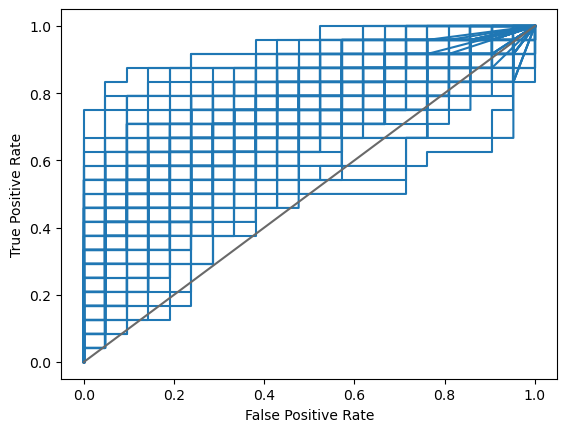

In [17]:
N_train = 800
N_validate = 200

dimensionality = 10

aucs2 = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100
                              ),
             tau_mean=0.5,
             tau_range=0.2,
             negative_tau=True)

aucs2

#experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

#auc_array = np.array(aucs)
#np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

In [19]:
np.quantile(aucs2, q=0.8)

0.8035714285714285

In [20]:
np.quantile(aucs2, q=0.2)

0.6753968253968254

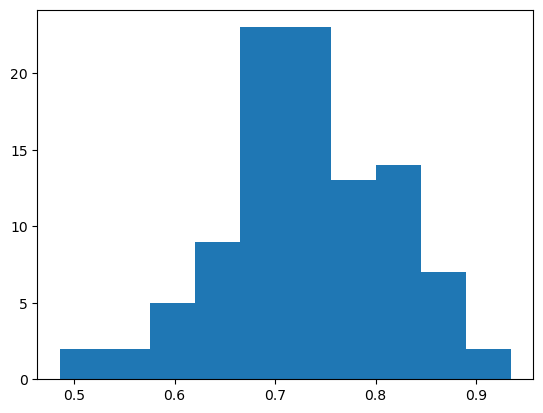

In [ ]:
plt.hist(aucs2)
plt.show()

  0%|          | 0/100 [00:00<?, ?it/s]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  1%|          | 1/100 [00:06<11:26,  6.93s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  3%|▎         | 3/100 [00:19<10:44,  6.65s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  4%|▍         | 4/100 [00:27<10:56,  6.84s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in

array([0.8968254 , 0.84722222, 0.84623016, 0.8859127 , 0.79365079,
       0.67857143, 0.79365079, 0.84325397, 0.71527778, 0.93253968,
       0.8452381 , 0.91071429, 0.85912698, 0.74007937, 0.80753968,
       0.67460317, 0.72718254, 0.72718254, 0.79563492, 0.67857143,
       0.79365079, 0.68353175, 0.5109127 , 0.75      , 0.7718254 ,
       0.68551587, 0.7827381 , 0.76190476, 0.84126984, 0.77380952,
       0.76388889, 0.87003968, 0.64980159, 0.75198413, 0.69246032,
       0.85515873, 0.70436508, 0.68353175, 0.80555556, 0.80952381,
       0.78769841, 0.62301587, 0.6765873 , 0.75198413, 0.74107143,
       0.83134921, 0.73809524, 0.83333333, 0.78769841, 0.73611111,
       0.63690476, 0.68253968, 0.70833333, 0.76984127, 0.84722222,
       0.73313492, 0.80357143, 0.79960317, 0.68849206, 0.66071429,
       0.66865079, 0.57142857, 0.68055556, 0.76190476, 0.73214286,
       0.88690476, 0.63888889, 0.64880952, 0.69246032, 0.75595238,
       0.78769841, 0.80952381, 0.76388889, 0.7609127 , 0.70634

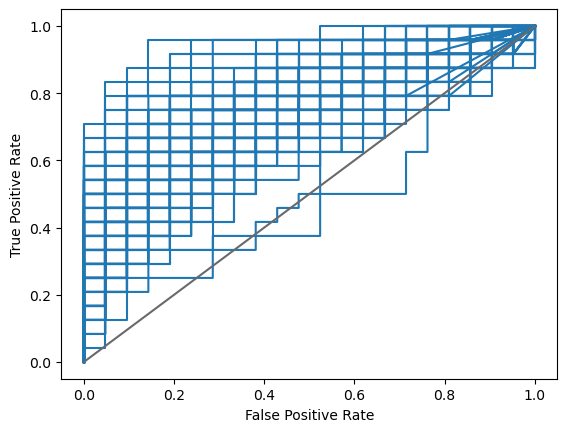

In [4]:
N_train = 800
N_validate = 200

dimensionality = 10

aucs2 = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100
                              ),
             tau_mean=0.5,
             tau_range=0.2,
             negative_tau=True)

aucs2

#experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

#auc_array = np.array(aucs)
#np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

In [7]:
np.quantile(aucs2, q=0.8)

0.8317460317460317

In [8]:
np.quantile(aucs2, q=0.2)

0.6878968253968254

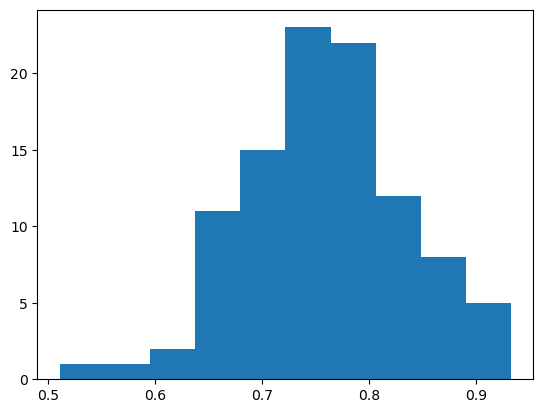

In [9]:
plt.hist(aucs2)
plt.show()

  2%|▏         | 2/100 [00:24<19:49, 12.14s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  5%|▌         | 5/100 [01:01<19:12, 12.13s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  6%|▌         | 6/100 [01:12<18:28, 11.79s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  7%|▋         | 7/100 [01:28<20:01, 12.92s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encoun

array([0.91269841, 0.8531746 , 0.85019841, 0.90376984, 0.80753968,
       0.67857143, 0.80555556, 0.83730159, 0.70634921, 0.93452381,
       0.87698413, 0.8125    , 0.8452381 , 0.7797619 , 0.7718254 ,
       0.70337302, 0.74404762, 0.75      , 0.79365079, 0.66468254,
       0.77579365, 0.68849206, 0.50793651, 0.76289683, 0.79563492,
       0.70833333, 0.7797619 , 0.73809524, 0.86507937, 0.79365079,
       0.81944444, 0.84722222, 0.66666667, 0.76388889, 0.75992063,
       0.90277778, 0.7202381 , 0.67460317, 0.81448413, 0.78968254,
       0.74702381, 0.61507937, 0.71031746, 0.76388889, 0.73015873,
       0.78571429, 0.73412698, 0.87301587, 0.78571429, 0.77380952,
       0.66666667, 0.68650794, 0.71031746, 0.74404762, 0.83730159,
       0.76785714, 0.79960317, 0.71825397, 0.6984127 , 0.69543651,
       0.69642857, 0.61011905, 0.65277778, 0.7797619 , 0.75595238,
       0.86706349, 0.64285714, 0.66666667, 0.73809524, 0.76587302,
       0.7797619 , 0.81944444, 0.75793651, 0.74007937, 0.69246

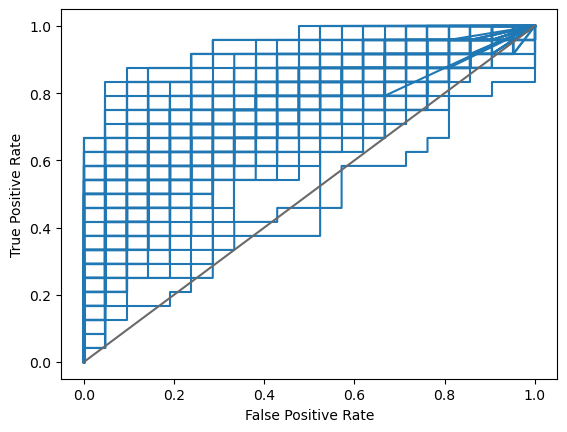

In [12]:
N_train = 25000
N_validate = 25000

dimensionality = 10

aucs2 = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=3,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,100
                              ),
             tau_mean=0.5,
             tau_range=0.2,
             negative_tau=True)

aucs2

#experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

#auc_array = np.array(aucs)
#np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

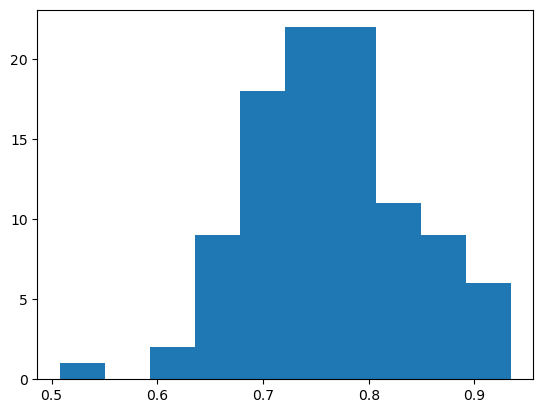

In [14]:
plt.hist(aucs2)
plt.show()

In [16]:
aucs2.mean()

0.7637301587301587

In [17]:
np.quantile(aucs2, q=0.8)

0.8194444444444444

In [18]:
np.quantile(aucs2, q=0.2)

0.7023809523809523

In [19]:
np.quantile(aucs2, q=0.95)

0.8990079365079365

In [20]:
np.quantile(aucs2, q=0.05)

0.6565476190476192

  0%|          | 0/30 [00:00<?, ?it/s]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  3%|▎         | 1/30 [00:07<03:29,  7.23s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
  7%|▋         | 2/30 [00:13<03:05,  6.62s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
 10%|█         | 3/30 [00:20<03:04,  6.81s/it]/Users/matthiasherp/anaconda3/envs/mctm_pytorch/lib/python3.11/site-packages/numpy/linalg/linalg.py:2120: RuntimeWarning: divide by zero encountered in slo

array([0.79555556, 0.80444444, 0.64888889, 0.79111111, 0.75222222,
       0.61555556, 0.63222222, 0.79111111, 0.63555556, 0.75222222,
       0.68666667, 0.74888889, 0.70666667, 0.69333333, 0.77111111,
       0.66666667, 0.62      , 0.67555556, 0.8       , 0.62666667,
       0.63777778, 0.64444444, 0.52      , 0.6       , 0.73777778,
       0.60444444, 0.71777778, 0.64777778, 0.75888889, 0.73333333])

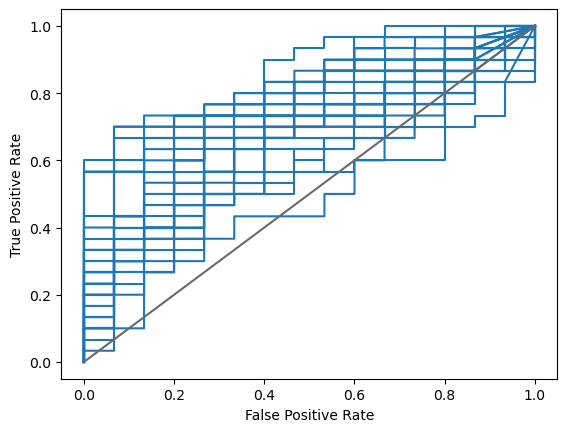

In [5]:
N_train = 800
N_validate = 200

dimensionality = 10

aucs2 = eval_ggm(N_train=N_train,
             N_validate=N_validate,
             N_test=10000,
             dimensionality = dimensionality,
             Independence_tree=4,
             vine_type="C-Vine",
             seed_value_copula_fixed=False,
             seed_range=range(0,30,#100
                              ),
             tau_mean=0.5,
             tau_range=0.2,
             negative_tau=True)

aucs2

#experiment_name="rvine_{}D_{}obs".format(dimensionality, N_train+N_validate)

#auc_array = np.array(aucs)
#np.save('ggm_auc_results_vines/'+experiment_name+'_auc_ggm.npy', auc_array)

In [8]:
np.mean(aucs2)

0.693888888888889

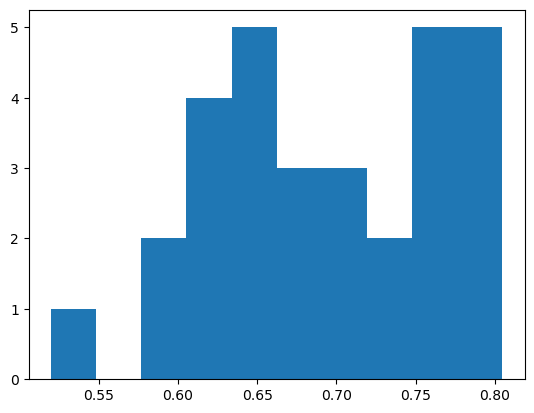

In [7]:
plt.hist(aucs2)
plt.show()

In [8]:
synthetic_data_dict = generate_synthetic_vine_data(
        seed_value=1,
        seed_value_copula=1,
        dimensionality=10,
        Independence_tree=2,
        vine_type="R-Vine",
        N_train=2000,
        N_validate=500,
        N_test=10000,
        tau_mean=0.3, 
        tau_range=0.2, 
        negative_tau=True
    )

synthetic_data_dict_2 = generate_synthetic_vine_data(
        seed_value=1,
        seed_value_copula=1,
        dimensionality=10,
        Independence_tree=2,
        vine_type="R-Vine",
        N_train=2000,
        N_validate=500,
        N_test=10000,
        tau_mean=0.3, 
        tau_range=0.2, 
        negative_tau=False
    )

synthetic_data_dict_3 = generate_synthetic_vine_data(
        seed_value=1,
        seed_value_copula=1,
        dimensionality=10,
        Independence_tree=2,
        vine_type="R-Vine",
        N_train=2000,
        N_validate=500,
        N_test=10000,
        tau_mean=0.5, 
        tau_range=0.2, 
        negative_tau=True
    )

In [5]:
from gtm import GTM
model = GTM(
        number_variables = 10,
        number_transformation_layers = 1,
        number_decorrelation_layers= 3,
        degree_transformations = 5,
        degree_decorrelation = 10,
        spline_transformation = "bspline",
        spline_decorrelation = "bspline",
        transformation_spline_range = (-5, 5),
        decorrelation_spline_range = (-10, 10),
        device = "cpu")

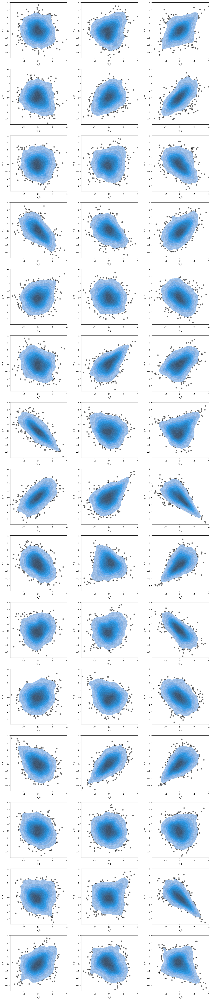

In [7]:
model.plot_densities(synthetic_data_dict["train_data"])

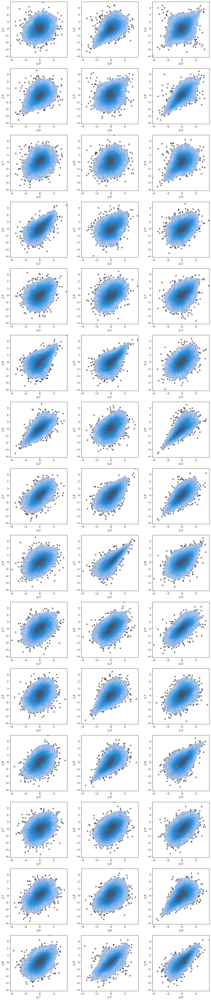

In [6]:
model.plot_densities(synthetic_data_dict_2["train_data"])

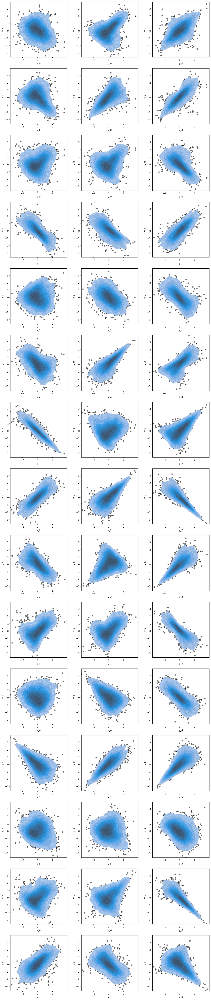

In [9]:
model.plot_densities(synthetic_data_dict_3["train_data"])